# BCLF Best-Candidate S-Parameter Range Comparison

Compare the best BCLF candidates found by BO, LHS, and TuRBO. This notebook only reads existing experiment artifacts: it does not submit jobs, run HFSS, or mutate queue state.

Outputs are saved under `experiments/bo_lhs_turbo_online_comparison/best_candidate_sp_range/`.

In [1]:
from __future__ import annotations

from pathlib import Path
import csv
import json
import math
import os
import re
import sys

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np

NOTEBOOK_DIR = Path.cwd()
REPO_ROOT = NOTEBOOK_DIR if (NOTEBOOK_DIR / 'experiments').exists() else NOTEBOOK_DIR.parent
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

OUTPUT_DIR = REPO_ROOT / 'experiments' / 'bo_lhs_turbo_online_comparison' / 'best_candidate_sp_range'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

METHOD_SOURCES = [
    {
        'label': 'BO',
        'method_id': 'global_gp_qlogei',
        'json_dir': REPO_ROOT / 'experiments' / 'bo_online_general',
        'color': 'tab:blue',
    },
    {
        'label': 'LHS',
        'method_id': 'lhs_random',
        'json_dir': REPO_ROOT / 'experiments' / 'lhs_online_general',
        'color': 'tab:orange',
    },
    {
        'label': 'TuRBO',
        'method_id': 'trust_region_gp_qlogei',
        'json_dir': REPO_ROOT / 'experiments' / 'turbo_online_general',
        'color': 'tab:green',
    },
]

FINAL_SUMMARY_CSV = REPO_ROOT / 'experiments' / 'bo_lhs_turbo_online_comparison' / 'bo_lhs_turbo_final_summary.csv'

PASSBAND = (4.8e9, 5.4e9)
LOW_STOPBAND = (3.6e9, 4.4e9)
HIGH_STOPBAND = (5.8e9, 8.7e9)
BANDS = {
    'Passband': PASSBAND,
    'Low stopband': LOW_STOPBAND,
    'High stopband': HIGH_STOPBAND,
}

plt.rcParams.update({
    'figure.dpi': 130,
    'savefig.dpi': 220,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

print('repo root:', REPO_ROOT)
print('output dir:', OUTPUT_DIR)

repo root: /home/zhanghf/projects/vector
output dir: /home/zhanghf/projects/vector/experiments/bo_lhs_turbo_online_comparison/best_candidate_sp_range


## Helpers

In [2]:
def repo_relative(path: Path | str | None) -> str | None:
    if path is None:
        return None
    p = Path(path)
    try:
        return str(p.resolve().relative_to(REPO_ROOT.resolve()))
    except ValueError:
        return str(p)


def resolve_existing_path(value: str | Path | None) -> Path | None:
    if value is None:
        return None
    path = Path(str(value))
    if path.exists():
        return path
    if not path.is_absolute():
        candidate = REPO_ROOT / path
        if candidate.exists():
            return candidate
    return None


def db20(values: np.ndarray) -> np.ndarray:
    return 20.0 * np.log10(np.maximum(np.abs(np.asarray(values)), 1e-15))


def band_mask(freq_hz: np.ndarray, band: tuple[float, float]) -> np.ndarray:
    return (freq_hz >= float(band[0])) & (freq_hz <= float(band[1]))


def parse_touchstone_s2p(path: Path) -> tuple[np.ndarray, np.ndarray]:
    # Lightweight Touchstone v1 parser. HFSS usually exports MA, but RI and DB
    # are supported so the notebook is not tied to one exporter setting.
    unit_scale = {'hz': 1.0, 'khz': 1e3, 'mhz': 1e6, 'ghz': 1e9}
    unit = 'ghz'
    data_format = 'ma'
    rows = []

    def pair_to_complex(first: float, second: float) -> complex:
        if data_format == 'ri':
            return complex(first, second)
        if data_format == 'ma':
            return float(first) * np.exp(1j * np.deg2rad(float(second)))
        if data_format == 'db':
            return (10.0 ** (float(first) / 20.0)) * np.exp(1j * np.deg2rad(float(second)))
        raise ValueError(f'Unsupported Touchstone data format: {data_format}')

    with path.open('r', encoding='utf-8', errors='ignore') as fh:
        for raw in fh:
            line = raw.split('!', 1)[0].strip()
            if not line:
                continue
            if line.startswith('#'):
                tokens = [token.lower() for token in line[1:].split()]
                for token in tokens:
                    if token in unit_scale:
                        unit = token
                    elif token in {'ri', 'ma', 'db'}:
                        data_format = token
                continue
            parts = line.split()
            if len(parts) < 9:
                continue
            rows.append([float(part) for part in parts[:9]])

    if not rows:
        raise ValueError(f'No Touchstone rows parsed from {path}')
    arr = np.asarray(rows, dtype=float)
    freq_hz = arr[:, 0] * unit_scale[unit]

    s_params = np.zeros((2, 2, len(freq_hz)), dtype=complex)
    # Touchstone 2-port row order is S11, S21, S12, S22.
    s_params[0, 0, :] = [pair_to_complex(a, b) for a, b in arr[:, 1:3]]
    s_params[1, 0, :] = [pair_to_complex(a, b) for a, b in arr[:, 3:5]]
    s_params[0, 1, :] = [pair_to_complex(a, b) for a, b in arr[:, 5:7]]
    s_params[1, 1, :] = [pair_to_complex(a, b) for a, b in arr[:, 7:9]]
    return freq_hz, s_params


def seed_from_path(path: Path) -> int | None:
    match = re.search(r'_seed(\d+)', path.stem)
    return None if match is None else int(match.group(1))


def format_cell(value) -> str:
    if value is None:
        return ''
    if isinstance(value, float):
        return f'{value:.6g}'
    if isinstance(value, list):
        formatted = [f'{item:.4g}' if isinstance(item, (int, float)) else str(item) for item in value]
        return '[' + ', '.join(formatted) + ']'
    text = str(value).replace('\n', ' ')
    return text.replace('|', '\\|')


def display_records(records: list[dict], columns: list[str] | None = None):
    if not records:
        display(Markdown('_No rows_'))
        return records
    columns = columns or list(records[0].keys())
    lines = [
        '| ' + ' | '.join(columns) + ' |',
        '| ' + ' | '.join('---' for _ in columns) + ' |',
    ]
    for row in records:
        lines.append('| ' + ' | '.join(format_cell(row.get(col)) for col in columns) + ' |')
    display(Markdown('\n'.join(lines)))
    return records


def write_records_csv(records: list[dict], path: Path) -> None:
    if not records:
        path.write_text('', encoding='utf-8')
        return
    columns = list(records[0].keys())
    with path.open('w', newline='', encoding='utf-8') as fh:
        writer = csv.DictWriter(fh, fieldnames=columns)
        writer.writeheader()
        writer.writerows(records)

## Select Best Candidate Per Algorithm

In [3]:
def iter_run_jsons(json_dir: Path) -> list[Path]:
    return sorted(
        path for path in json_dir.glob('*.json')
        if not path.name.endswith('.checkpoint.json')
    )


def select_global_best_candidate(source: dict) -> dict:
    best = None
    for run_json in iter_run_jsons(source['json_dir']):
        payload = json.loads(run_json.read_text(encoding='utf-8'))
        seed = seed_from_path(run_json)
        for trial in payload.get('trials', []):
            try:
                objective = float(trial.get('objective'))
            except (TypeError, ValueError):
                continue
            if not math.isfinite(objective):
                continue
            if trial.get('simulation_status') not in {None, 'done'}:
                continue
            metadata = trial.get('simulation_metadata') or {}
            touchstone = resolve_existing_path(metadata.get('touchstone_path'))
            if touchstone is None:
                continue
            row = {
                'method': source['label'],
                'method_id': source['method_id'],
                'seed': seed,
                'run_json': run_json,
                'case_id': trial.get('case_id'),
                'job_id': trial.get('job_id'),
                'iteration': trial.get('iteration'),
                'phase': trial.get('phase'),
                'objective': objective,
                'geometry': trial.get('geometry'),
                'cache_hit': trial.get('cache_hit'),
                'touchstone_path': touchstone,
                'trial': trial,
                'color': source['color'],
            }
            if best is None or row['objective'] < best['objective']:
                best = row
    if best is None:
        raise RuntimeError(f"No best candidate with an existing Touchstone found for {source['label']}")
    return best


best_candidates = [select_global_best_candidate(source) for source in METHOD_SOURCES]
best_rows = [
    {
        'method': row['method'],
        'method_id': row['method_id'],
        'seed': row['seed'],
        'iteration': row['iteration'],
        'objective': row['objective'],
        'case_id': row['case_id'],
        'cache_hit': row['cache_hit'],
        'geometry': row['geometry'],
        'touchstone_path': repo_relative(row['touchstone_path']),
        'run_json': repo_relative(row['run_json']),
    }
    for row in best_candidates
]
display_records(
    best_rows,
    columns=['method', 'method_id', 'seed', 'iteration', 'objective', 'case_id', 'cache_hit', 'geometry', 'touchstone_path'],
)

| method | method_id | seed | iteration | objective | case_id | cache_hit | geometry | touchstone_path |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| BO | global_gp_qlogei | 1 | 38 | -23.8139 | bo_online_general_seed1_it0038 | True | [7.79, 8.15, 7.95, 1.05, 0.86, 1.01, 0.16, 0.59] | data/bandpass_coupled_line_filter_export/ext/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d79_L1_8d15_L2_7d95_W_1d05_W1_0d86_W2_1d01_S1_0d16_S2_0d59.s2p |
| LHS | lhs_random | 0 | 23 | -25.1413 | lhs_online_general_seed0_it0023 | True | [7.82, 8.17, 7.91, 1.07, 0.85, 1.1, 0.14, 0.58] | data/bandpass_coupled_line_filter_export/ext/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d82_L1_8d17_L2_7d91_W_1d07_W1_0d85_W2_1d1_S1_0d14_S2_0d58.s2p |
| TuRBO | trust_region_gp_qlogei | 3 | 59 | -22.5171 | turbo_online_general_seed3_it0059 | True | [7.82, 8.18, 7.99, 1, 0.85, 1.05, 0.14, 0.59] | data/bandpass_coupled_line_filter_export/ext/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d82_L1_8d18_L2_7d99_W_1d0_W1_0d85_W2_1d05_S1_0d14_S2_0d59.s2p |

[{'method': 'BO',
  'method_id': 'global_gp_qlogei',
  'seed': 1,
  'iteration': 38,
  'objective': -23.813876555051976,
  'case_id': 'bo_online_general_seed1_it0038',
  'cache_hit': True,
  'geometry': [7.79, 8.15, 7.95, 1.05, 0.86, 1.01, 0.16, 0.59],
  'touchstone_path': 'data/bandpass_coupled_line_filter_export/ext/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d79_L1_8d15_L2_7d95_W_1d05_W1_0d86_W2_1d01_S1_0d16_S2_0d59.s2p',
  'run_json': 'experiments/bo_online_general/bo_online_general_seed1.json'},
 {'method': 'LHS',
  'method_id': 'lhs_random',
  'seed': 0,
  'iteration': 23,
  'objective': -25.141274861871228,
  'case_id': 'lhs_online_general_seed0_it0023',
  'cache_hit': True,
  'geometry': [7.82, 8.17, 7.91, 1.07, 0.85, 1.1, 0.14, 0.58],
  'touchstone_path': 'data/bandpass_coupled_line_filter_export/ext/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d82_L1_8d17_L2_7d91_W_1d07_W1_0d85_W2_1d1_S1_0d14_S2_0d58.s2p',
  'run_json': 'experime

## Load Best-Candidate Touchstone Responses

In [4]:
responses = {}
for row in best_candidates:
    freq_hz, s_params = parse_touchstone_s2p(row['touchstone_path'])
    if s_params.shape != (2, 2, len(freq_hz)):
        raise AssertionError(f"Unexpected S-parameter shape for {row['method']}: {s_params.shape}")
    if not np.all(np.isfinite(db20(s_params))):
        raise AssertionError(f"Non-finite dB response for {row['method']}")
    responses[row['method']] = {
        'freq_hz': freq_hz,
        's_params': s_params,
        'color': row['color'],
        'objective': row['objective'],
    }

response_rows = [
    {
        'method': method,
        'freq_rows': len(payload['freq_hz']),
        'freq_min_ghz': payload['freq_hz'][0] / 1e9,
        'freq_max_ghz': payload['freq_hz'][-1] / 1e9,
        's_shape': str(payload['s_params'].shape),
    }
    for method, payload in responses.items()
]
display_records(response_rows)

| method | freq_rows | freq_min_ghz | freq_max_ghz | s_shape |
| --- | --- | --- | --- | --- |
| BO | 401 | 3.5 | 8.7 | (2, 2, 401) |
| LHS | 401 | 3.5 | 8.7 | (2, 2, 401) |
| TuRBO | 401 | 3.5 | 8.7 | (2, 2, 401) |

[{'method': 'BO',
  'freq_rows': 401,
  'freq_min_ghz': np.float64(3.5),
  'freq_max_ghz': np.float64(8.7),
  's_shape': '(2, 2, 401)'},
 {'method': 'LHS',
  'freq_rows': 401,
  'freq_min_ghz': np.float64(3.5),
  'freq_max_ghz': np.float64(8.7),
  's_shape': '(2, 2, 401)'},
 {'method': 'TuRBO',
  'freq_rows': 401,
  'freq_min_ghz': np.float64(3.5),
  'freq_max_ghz': np.float64(8.7),
  's_shape': '(2, 2, 401)'}]

## Full-Band Best-Candidate S-Parameter Curves

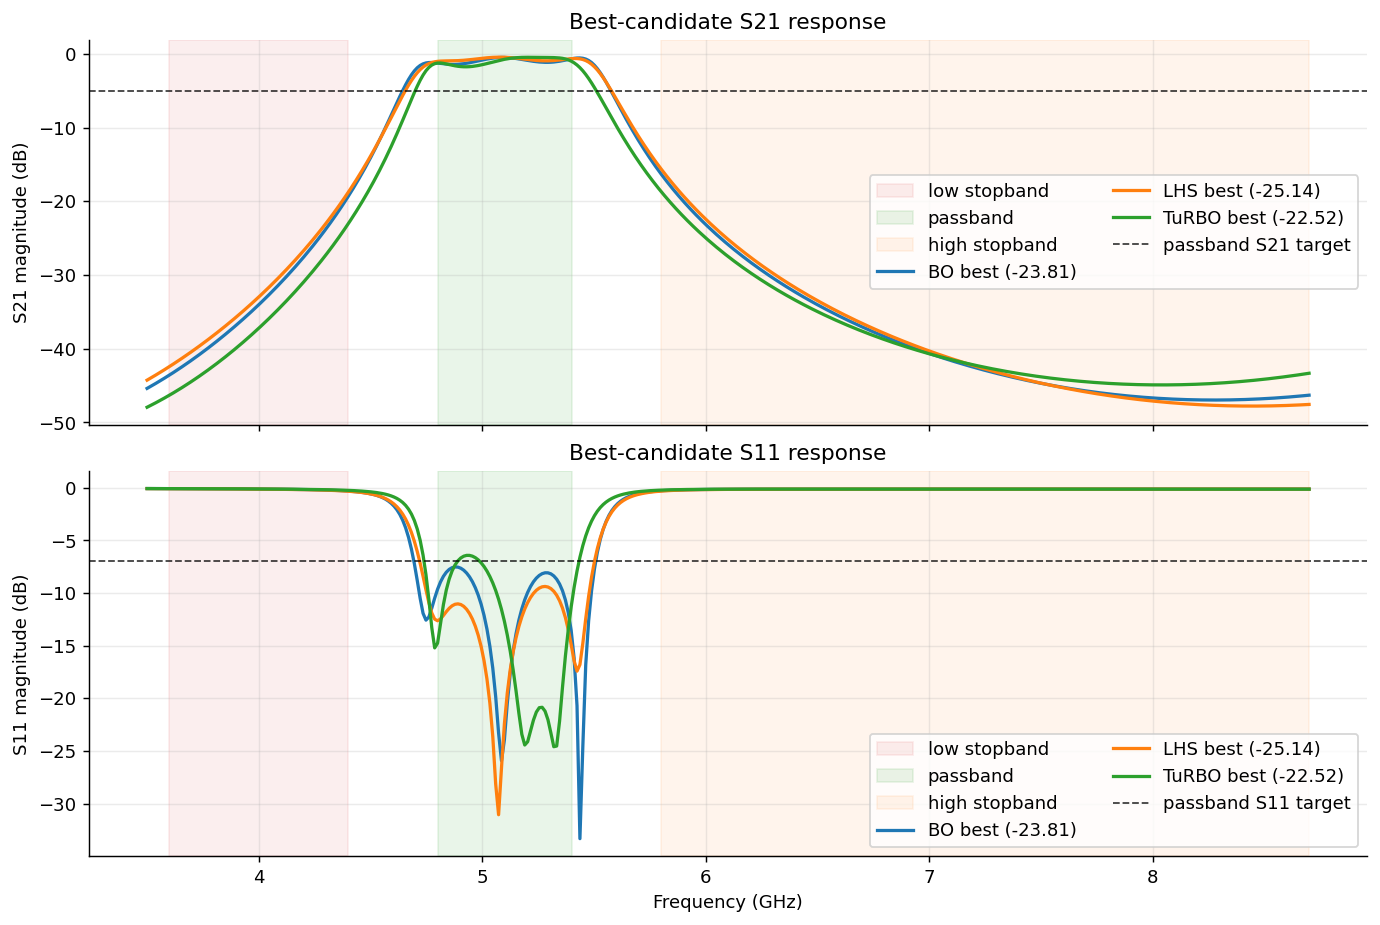

saved: experiments/bo_lhs_turbo_online_comparison/best_candidate_sp_range/bclf_best_candidate_s11_s21_fullband.png


In [5]:
def shade_bands(ax):
    ax.axvspan(LOW_STOPBAND[0] / 1e9, LOW_STOPBAND[1] / 1e9, color='tab:red', alpha=0.08, label='low stopband')
    ax.axvspan(PASSBAND[0] / 1e9, PASSBAND[1] / 1e9, color='tab:green', alpha=0.10, label='passband')
    ax.axvspan(HIGH_STOPBAND[0] / 1e9, HIGH_STOPBAND[1] / 1e9, color='tab:orange', alpha=0.08, label='high stopband')


fig, axes = plt.subplots(2, 1, figsize=(10.5, 7.0), sharex=True, constrained_layout=True)

for ax, channel, idx, target, target_label in [
    (axes[0], 'S21', (1, 0), -5.0, 'passband S21 target'),
    (axes[1], 'S11', (0, 0), -7.0, 'passband S11 target'),
]:
    shade_bands(ax)
    for row in best_candidates:
        payload = responses[row['method']]
        freq_ghz = payload['freq_hz'] / 1e9
        values_db = db20(payload['s_params'][idx[0], idx[1], :])
        ax.plot(
            freq_ghz,
            values_db,
            label=f"{row['method']} best ({row['objective']:.2f})",
            color=row['color'],
            linewidth=1.8,
        )
    ax.axhline(target, color='black', linestyle='--', linewidth=1.0, alpha=0.75, label=target_label)
    ax.set_ylabel(f'{channel} magnitude (dB)')
    ax.set_title(f'Best-candidate {channel} response')
    ax.legend(loc='best', ncols=2)

axes[-1].set_xlabel('Frequency (GHz)')
fullband_path = OUTPUT_DIR / 'bclf_best_candidate_s11_s21_fullband.png'
fig.savefig(fullband_path, bbox_inches='tight')
plt.show()
print('saved:', repo_relative(fullband_path))

## Band Metrics For The Best Candidates

In [6]:
def channel_stats(freq_hz: np.ndarray, values_db: np.ndarray, band: tuple[float, float]) -> tuple[float, float, float]:
    mask = band_mask(freq_hz, band)
    if not np.any(mask):
        raise ValueError(f'No frequency rows inside band {band}')
    band_values = np.asarray(values_db[mask], dtype=float)
    return float(np.min(band_values)), float(np.mean(band_values)), float(np.max(band_values))


metric_specs = [
    {
        'metric': 'passband_s21',
        'label': 'Passband S21',
        'band': PASSBAND,
        'channel': 'S21',
        'index': (1, 0),
        'target_db': -5.0,
        'constraint': 'min >= -5 dB',
    },
    {
        'metric': 'passband_s11',
        'label': 'Passband S11',
        'band': PASSBAND,
        'channel': 'S11',
        'index': (0, 0),
        'target_db': -7.0,
        'constraint': 'max <= -7 dB',
    },
    {
        'metric': 'low_stopband_s21',
        'label': 'Low stopband S21',
        'band': LOW_STOPBAND,
        'channel': 'S21',
        'index': (1, 0),
        'target_db': -15.0,
        'constraint': 'max <= -15 dB',
    },
    {
        'metric': 'high_stopband_s21',
        'label': 'High stopband S21',
        'band': HIGH_STOPBAND,
        'channel': 'S21',
        'index': (1, 0),
        'target_db': -15.0,
        'constraint': 'max <= -15 dB',
    },
]

metric_rows = []
for candidate in best_candidates:
    payload = responses[candidate['method']]
    for spec in metric_specs:
        row, col = spec['index']
        values_db = db20(payload['s_params'][row, col, :])
        min_db, mean_db, max_db = channel_stats(payload['freq_hz'], values_db, spec['band'])
        metric_rows.append({
            'method': candidate['method'],
            'metric': spec['metric'],
            'label': spec['label'],
            'channel': spec['channel'],
            'band_ghz': f"{spec['band'][0] / 1e9:.1f}-{spec['band'][1] / 1e9:.1f}",
            'min_db': min_db,
            'mean_db': mean_db,
            'max_db': max_db,
            'target_db': spec['target_db'],
            'constraint': spec['constraint'],
            'objective': candidate['objective'],
        })

metrics_path = OUTPUT_DIR / 'bclf_best_candidate_band_metrics.csv'
write_records_csv(metric_rows, metrics_path)
display_records(
    metric_rows,
    columns=['method', 'label', 'band_ghz', 'min_db', 'mean_db', 'max_db', 'target_db', 'constraint', 'objective'],
)

| method | label | band_ghz | min_db | mean_db | max_db | target_db | constraint | objective |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| BO | Passband S21 | 4.8-5.4 | -1.44023 | -0.968578 | -0.488391 | -5 | min >= -5 dB | -23.8139 |
| BO | Passband S11 | 4.8-5.4 | -25.9413 | -11.4858 | -7.51834 | -7 | max <= -7 dB | -23.8139 |
| BO | Low stopband S21 | 3.6-4.4 | -43.5019 | -33.1826 | -19.4875 | -15 | max <= -15 dB | -23.8139 |
| BO | High stopband S21 | 5.8-8.7 | -46.9672 | -39.4344 | -16.3283 | -15 | max <= -15 dB | -23.8139 |
| LHS | Passband S21 | 4.8-5.4 | -1.01987 | -0.75627 | -0.452752 | -5 | min >= -5 dB | -25.1413 |
| LHS | Passband S11 | 4.8-5.4 | -31.0631 | -13.9611 | -9.37199 | -7 | max <= -7 dB | -25.1413 |
| LHS | Low stopband S21 | 3.6-4.4 | -42.3473 | -32.1946 | -18.9322 | -15 | max <= -15 dB | -25.1413 |
| LHS | High stopband S21 | 5.8-8.7 | -47.7872 | -39.3949 | -15.6458 | -15 | max <= -15 dB | -25.1413 |
| TuRBO | Passband S21 | 4.8-5.4 | -1.75883 | -0.98677 | -0.469865 | -5 | min >= -5 dB | -22.5171 |
| TuRBO | Passband S11 | 4.8-5.4 | -24.5995 | -14.3639 | -6.41941 | -7 | max <= -7 dB | -22.5171 |
| TuRBO | Low stopband S21 | 3.6-4.4 | -46.2389 | -36.3784 | -23.1942 | -15 | max <= -15 dB | -22.5171 |
| TuRBO | High stopband S21 | 5.8-8.7 | -44.9167 | -39.023 | -18.7045 | -15 | max <= -15 dB | -22.5171 |

[{'method': 'BO',
  'metric': 'passband_s21',
  'label': 'Passband S21',
  'channel': 'S21',
  'band_ghz': '4.8-5.4',
  'min_db': -1.4402326811251829,
  'mean_db': -0.968577890186757,
  'max_db': -0.4883907183350466,
  'target_db': -5.0,
  'constraint': 'min >= -5 dB',
  'objective': -23.813876555051976},
 {'method': 'BO',
  'metric': 'passband_s11',
  'label': 'Passband S11',
  'channel': 'S11',
  'band_ghz': '4.8-5.4',
  'min_db': -25.941250403208276,
  'mean_db': -11.485787115078846,
  'max_db': -7.518342422497827,
  'target_db': -7.0,
  'constraint': 'max <= -7 dB',
  'objective': -23.813876555051976},
 {'method': 'BO',
  'metric': 'low_stopband_s21',
  'label': 'Low stopband S21',
  'channel': 'S21',
  'band_ghz': '3.6-4.4',
  'min_db': -43.501913351127506,
  'mean_db': -33.182613543530955,
  'max_db': -19.487470782373933,
  'target_db': -15.0,
  'constraint': 'max <= -15 dB',
  'objective': -23.813876555051976},
 {'method': 'BO',
  'metric': 'high_stopband_s21',
  'label': 'High 

## Band-Metric Range Bars

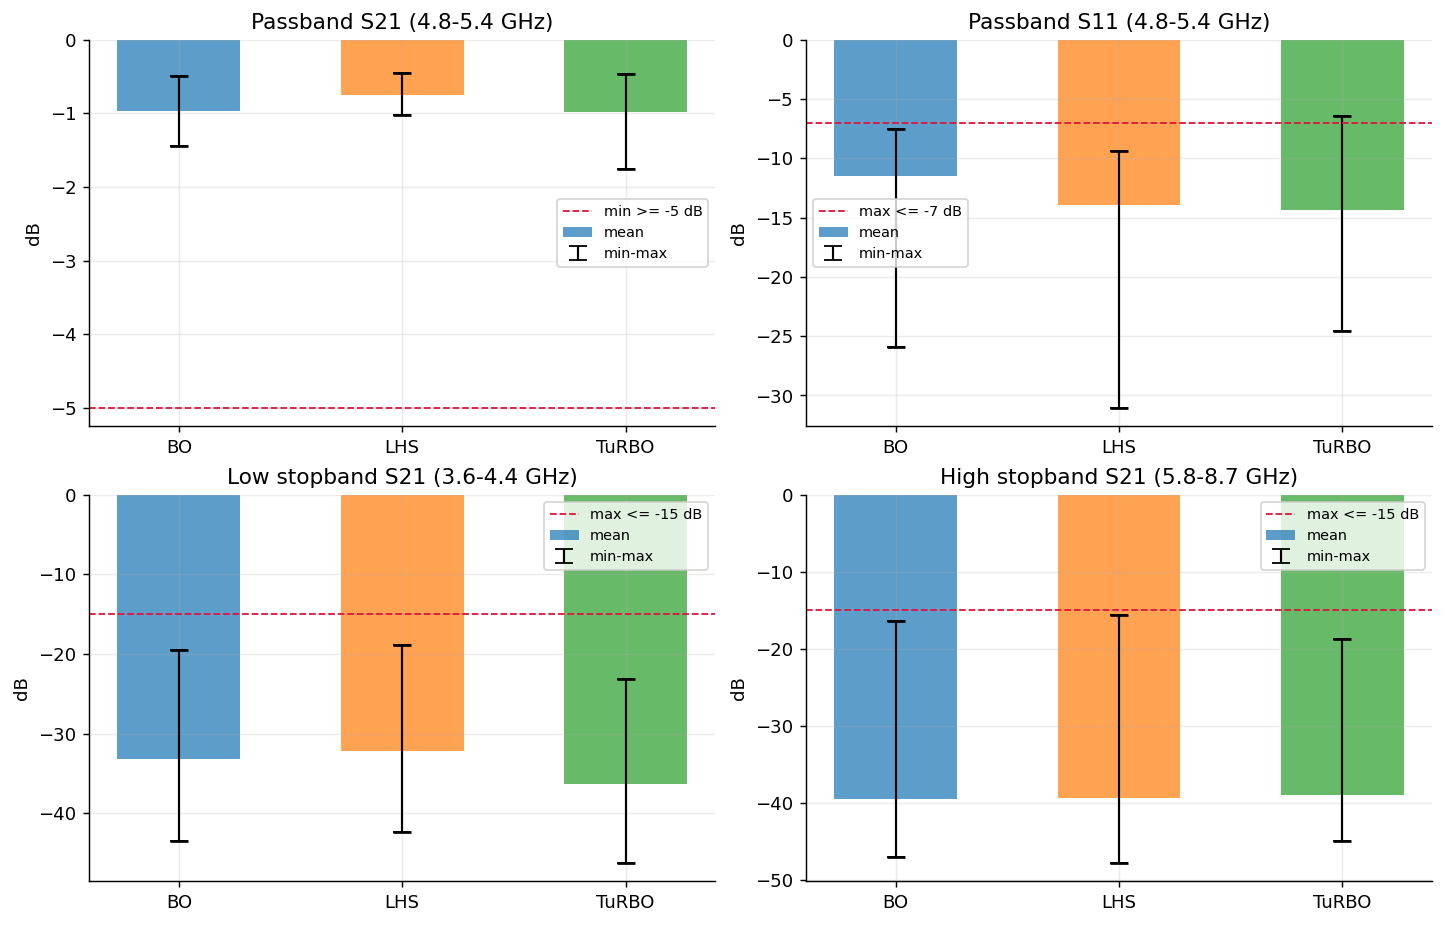

saved: experiments/bo_lhs_turbo_online_comparison/best_candidate_sp_range/bclf_best_candidate_band_metric_range_bars.png


In [7]:
method_order = [source['label'] for source in METHOD_SOURCES]
color_lookup = {source['label']: source['color'] for source in METHOD_SOURCES}

fig, axes = plt.subplots(2, 2, figsize=(11.0, 7.0), constrained_layout=True)
axes = axes.ravel()

for ax, spec in zip(axes, metric_specs):
    subset = [
        next(row for row in metric_rows if row['metric'] == spec['metric'] and row['method'] == method)
        for method in method_order
    ]
    x = np.arange(len(subset), dtype=float)
    y = np.asarray([row['mean_db'] for row in subset], dtype=float)
    min_values = np.asarray([row['min_db'] for row in subset], dtype=float)
    max_values = np.asarray([row['max_db'] for row in subset], dtype=float)
    lower = y - min_values
    upper = max_values - y
    colors = [color_lookup[row['method']] for row in subset]
    ax.bar(x, y, color=colors, alpha=0.72, width=0.55, label='mean')
    ax.errorbar(x, y, yerr=np.vstack([lower, upper]), fmt='none', ecolor='black', elinewidth=1.2, capsize=5, label='min-max')
    ax.scatter(x, min_values, marker='_', color='black', s=90, zorder=4)
    ax.scatter(x, max_values, marker='_', color='black', s=90, zorder=4)
    ax.axhline(spec['target_db'], color='crimson', linestyle='--', linewidth=1.0, label=spec['constraint'])
    ax.set_xticks(x, [row['method'] for row in subset])
    ax.set_ylabel('dB')
    ax.set_title(f"{spec['label']} ({spec['band'][0] / 1e9:.1f}-{spec['band'][1] / 1e9:.1f} GHz)")
    ax.legend(loc='best', fontsize=8)

range_bar_path = OUTPUT_DIR / 'bclf_best_candidate_band_metric_range_bars.png'
fig.savefig(range_bar_path, bbox_inches='tight')
plt.show()
print('saved:', repo_relative(range_bar_path))

## Final Objective Summary Across Seeds

In [8]:
with FINAL_SUMMARY_CSV.open('r', newline='', encoding='utf-8') as fh:
    final_summary_rows = list(csv.DictReader(fh))
display_records(final_summary_rows)

| method | n | median_best_objective | mean_best_objective | best_min_objective | worst_max_objective | median_cache_hit_ratio | median_runtime_engine_sec | median_runtime_sim_sec | total_failed_rows |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| BO | 5 | -14.657113975239028 | -15.64937645301543 | -23.813876555051976 | -8.052391496569719 | 1.0 | 36.63878988032229 | 10.279869712423531 | 3 |
| LHS | 5 | -19.16188497901864 | -18.814976094984143 | -25.141274861871228 | -9.847342584085244 | 0.15 | 2.612550328485668 | 36469.7371429042 | 7 |
| Turbo | 5 | -19.16097877308988 | -17.523540572387965 | -22.517094163213606 | -9.206406075002814 | 1.0 | 47.64410441508517 | 9.088846492115408 | 4 |

[{'method': 'BO',
  'n': '5',
  'median_best_objective': '-14.657113975239028',
  'mean_best_objective': '-15.64937645301543',
  'best_min_objective': '-23.813876555051976',
  'worst_max_objective': '-8.052391496569719',
  'median_cache_hit_ratio': '1.0',
  'median_runtime_engine_sec': '36.63878988032229',
  'median_runtime_sim_sec': '10.279869712423531',
  'total_failed_rows': '3'},
 {'method': 'LHS',
  'n': '5',
  'median_best_objective': '-19.16188497901864',
  'mean_best_objective': '-18.814976094984143',
  'best_min_objective': '-25.141274861871228',
  'worst_max_objective': '-9.847342584085244',
  'median_cache_hit_ratio': '0.15',
  'median_runtime_engine_sec': '2.612550328485668',
  'median_runtime_sim_sec': '36469.7371429042',
  'total_failed_rows': '7'},
 {'method': 'Turbo',
  'n': '5',
  'median_best_objective': '-19.16097877308988',
  'mean_best_objective': '-17.523540572387965',
  'best_min_objective': '-22.517094163213606',
  'worst_max_objective': '-9.206406075002814',
  

In [9]:
summary_payload = {
    'best_candidates': best_rows,
    'band_metrics_csv': repo_relative(metrics_path),
    'fullband_plot': repo_relative(fullband_path),
    'range_bar_plot': repo_relative(range_bar_path),
    'final_summary_csv': repo_relative(FINAL_SUMMARY_CSV),
}
summary_path = OUTPUT_DIR / 'bclf_best_candidate_sp_range_summary.json'
summary_path.write_text(json.dumps(summary_payload, indent=2), encoding='utf-8')
summary_payload

{'best_candidates': [{'method': 'BO',
   'method_id': 'global_gp_qlogei',
   'seed': 1,
   'iteration': 38,
   'objective': -23.813876555051976,
   'case_id': 'bo_online_general_seed1_it0038',
   'cache_hit': True,
   'geometry': [7.79, 8.15, 7.95, 1.05, 0.86, 1.01, 0.16, 0.59],
   'touchstone_path': 'data/bandpass_coupled_line_filter_export/ext/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d79_L1_8d15_L2_7d95_W_1d05_W1_0d86_W2_1d01_S1_0d16_S2_0d59.s2p',
   'run_json': 'experiments/bo_online_general/bo_online_general_seed1.json'},
  {'method': 'LHS',
   'method_id': 'lhs_random',
   'seed': 0,
   'iteration': 23,
   'objective': -25.141274861871228,
   'case_id': 'lhs_online_general_seed0_it0023',
   'cache_hit': True,
   'geometry': [7.82, 8.17, 7.91, 1.07, 0.85, 1.1, 0.14, 0.58],
   'touchstone_path': 'data/bandpass_coupled_line_filter_export/ext/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d82_L1_8d17_L2_7d91_W_1d07_W1_0d85_W2_1d1_S1_0d14